In questo notebook provvisorio inserisco immagini relative ai grafici utili per il confronto delle sessioni di training dell'agente con e senza Probabilistic Policy Reuse

L'obbiettivo è dimostrare che l'utilizzo di ppr porti l'agente ad adattarsi più rapidamente all'env rispetto a partire da zero, e quindi a massimizzare la ricompensa (e quindi la lifetime del qubit logico) in meno tempo

Il paper originale (https://arxiv.org/pdf/2212.11890) confronta semplicemente i grafici relativi alla media mobile di lifetime per episodi, mostrando come l'agente ppr raggiunga livelli simili o maggiori a quello "by scratch" in meno episodi



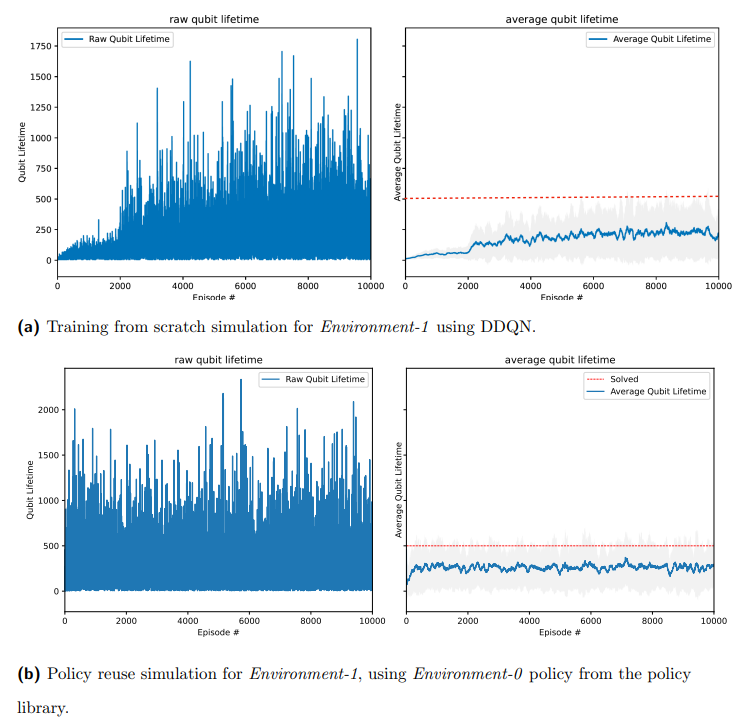 

[immagine tratta dal paper originale che introduce PPR]

Purtroppo non fornisce indicazioni riguardo a come viene gestito il comportamento di eps durante la durata di una sessione di training e, a differenza di quanto ho fatto io, allena l'agente su un numero fisso di 10000 episodi, con 1000 steps massimo per singolo episodio

Io ho deciso, sulla base anche di quanto proposto nel repo da cui ho tratto l'env, di implementare una politica di eps-annealing lineare, con un valore che va da 1 a 0.02 in 75000 steps, su sessioni di training di durata maxtimesteps = 1000000

Al momento dispongo di una libreria di policy addestrate "by scratch" per env  con p_err=0.001, 0.003, 0.005, 0.007, 0.009 con questo annullamento di eps

Per garantire un confronto reale tra le due tipologie di addestramento ritengo quindi quanto meno necessario dover utilizzare lo stesso eps-annealing, implementando una adeguata politica di psi-annealing, parametro che invece determina il riutilizzo o meno di azioni prese da politiche passate in ppr.

L'addestramento secondo ppr è basato su questo ciclo:
Per ogni episodio:

viene estratta una policy: k=0 quella in allenamento, k>0 una preaddestrata dalla lib 
- se k=0, vengono eseguiti steps (fino alla fine dell'episodio) secondo il classico modello di apprendimento con eps-greedy sulla policy in allenamento
- se k>0, per ogni step:
- - viene selezionata con probabilità psi la miglior azione per lo stato attuale secondo dalla policy preaddestrata 
- - altrimenti con probabilità (1-psi) viene eseguito uno step con eps-greedy sulla policy in allenamento


Inoltre ritengo di dover confrontare piuttosto che lifetime media vs episodio, lifetime media vs timestep (gli step cumulativi dall'inizio del train), che rappresentano le singole vere interazioni che il mio agente ha avuto con l'env: l'utilizzo di policy passate infatti garantisce in ogni caso una durata degli episodi maggiore nelle prime fasi dell'addestramento e quindi un "consumo" più rapido degli step necessari a completare la fase di esplorazione (eps 1-->0.02) e dunque una convergenza più rapida in termini di episodi. Per dimostrare un miglior adattamento dell'agente al nuovo env quindi ritengo che dovrei ottenere un pari (o superiore) livello di vitamedia in meno step piuttosto che episodi.


Per semplicità del modello, pensavo di mantenere un annullamento lineare del valore di psi. Di seguito un grafico rappresentativo

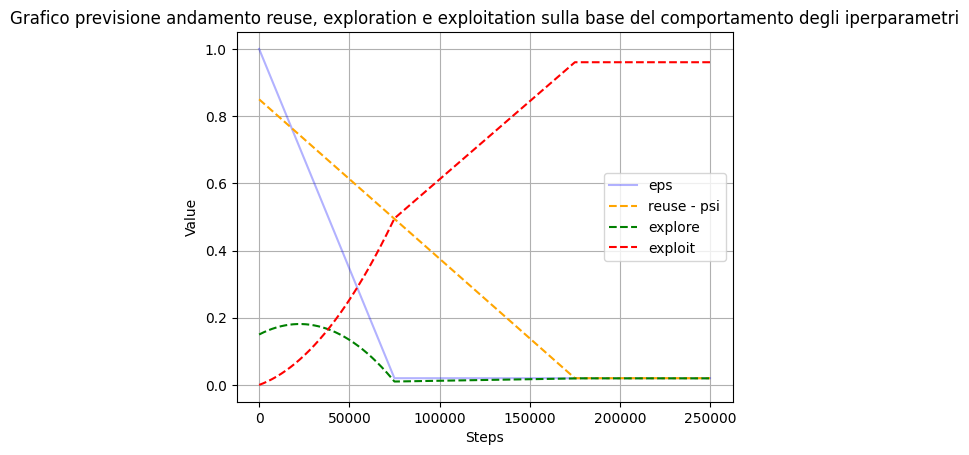

In [4]:
# Grafico previsione andamento reuse, exploration e exploitation sulla base del comportamento degli iperparametri
import matplotlib.pyplot as plt
import numpy as np

# comportamento eps: da mantenere questo se voglio garantire un confronto veritiero con gli agenti allenati senza ppr
def eps (step, max_eps=1.0, final_eps=0.02, exploration_fraction=75000):
    """Calcola il valore di epsilon per l'esplorazione decrescente."""
    if step >= exploration_fraction:
        return final_eps
    else:
        return max_eps - (max_eps - final_eps) * (step / exploration_fraction)

# comportamento psi: da studiare
def psi (step, max_psi=0.85, final_psi=0.02, exploration_fraction=175000):
    """Calcola il valore di psi per l'esplorazione decrescente."""
    return max(final_psi, max_psi - (max_psi - final_psi) * ((step)  / exploration_fraction))

steps = np.arange(0, 250000, 100)
eps_values = np.array([eps(step) for step in steps])
psi_values = np.array([psi(step) for step in steps])
plt.plot(steps, eps_values, label='eps', color='blue', alpha=0.3)
plt.plot(steps, psi_values, label='reuse - psi', color='orange', linestyle='--')
plt.plot(steps, (1-psi_values)*eps_values, label='explore', color='green', linestyle='--')
plt.plot(steps, (1-psi_values)*(1-eps_values), label='exploit', color='red', linestyle='--')
plt.xlabel('Steps')
plt.ylabel('Value')
plt.title('Grafico previsione andamento reuse, exploration e exploitation sulla base del comportamento degli iperparametri')
plt.legend()
plt.grid()
plt.show()    

# Confronto Grafici

Ho eseguito pochi test con ppr, solo su env 0.003 e 0.005. In particolare ho provato un paio di di soluzioni per l'annullamento lineare di psi e di seguito riporto i miei risultati.

I grafici migliori (sotto riportati) ritengo di averli ottenuti considerando un annealing per psi del tipo 0.85 --> 0.02 in 175000 steps (come nel precedente plot). In questo modo l'agente ha modo di riutilizzare con maggior probabilità azioni di policy preaddestrate in una prima fase, ma è comunque garantito uno sfruttamento piuttosto rapido rispetto alla durata del train per favorire la convergenza

NB: poichè ho utilizzato una lifetime media mobile calcolata sugli ultimi 500 ep, i primi valori di lifetime per ciacun grafico non sono attendibili poichè calcolati su una finestra minore. Ho deciso di calcolarli comunque per avede un'idea, seppur non troppo affidabile, di come si comporta l'agente anche sui primissimi episodi

# Env con p_err = 0.003

Questi sono i grafici (di interesse per il confronto) relativi all'addestramento dell'agente by scratch per ambiente con p_err=0.003:

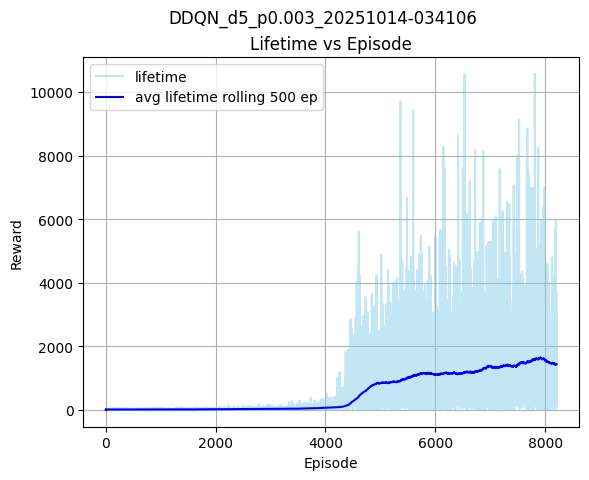
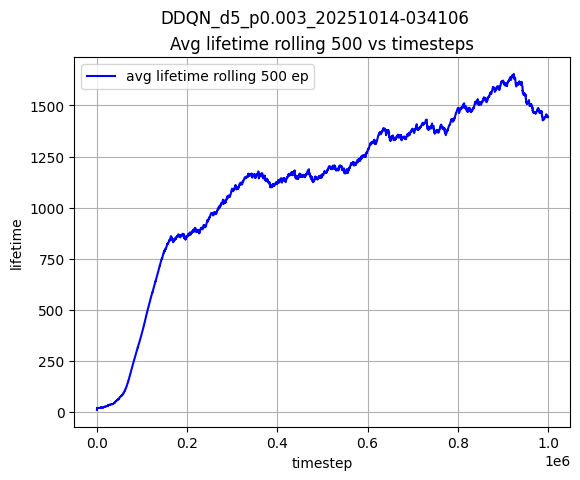

Mentre questi sono i grafici relativi all'addestramento con ppr nello stesso env e utilizzando una libreria di policy preaddestrate con 1 solo modello [quello relativo a p_err=0.001], utilizzando l'annealing per psi 0.85-->0.02 in 175k 

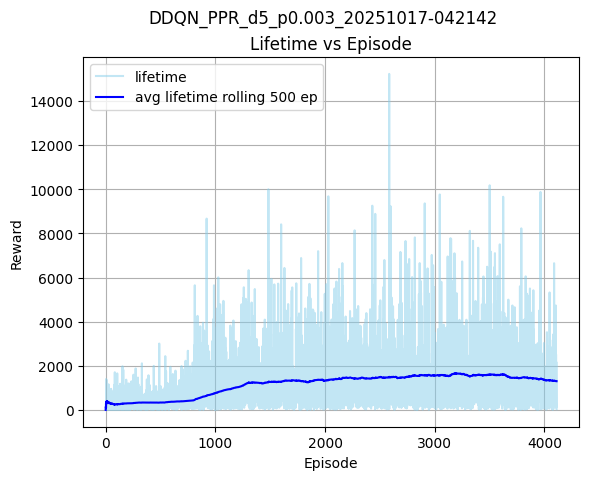
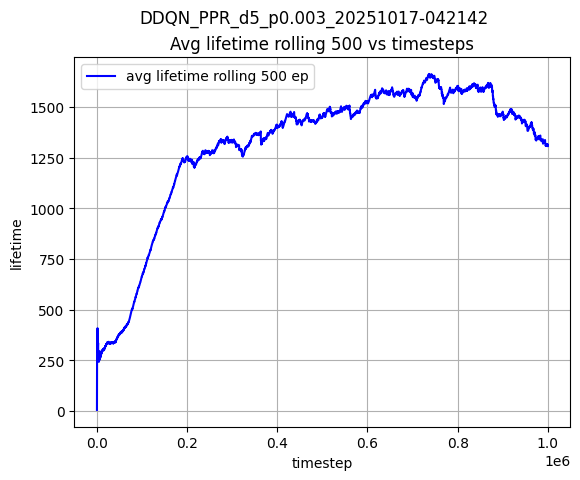

# Env con p_err = 0.005

Questi sono i grafici (di interesse per il confronto) relativi all'addestramento dell'agente by scratch per ambiente con p_err=0.005:

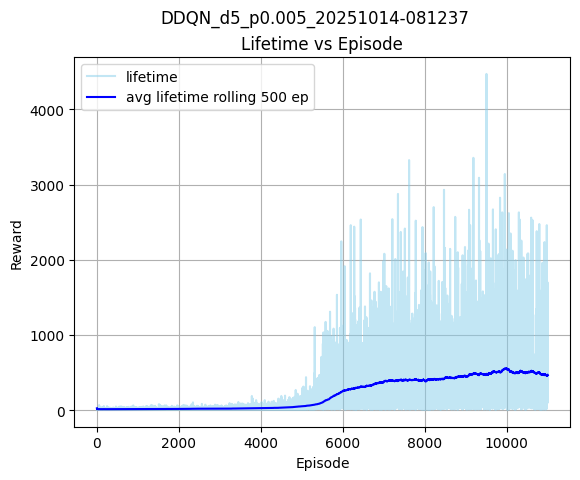
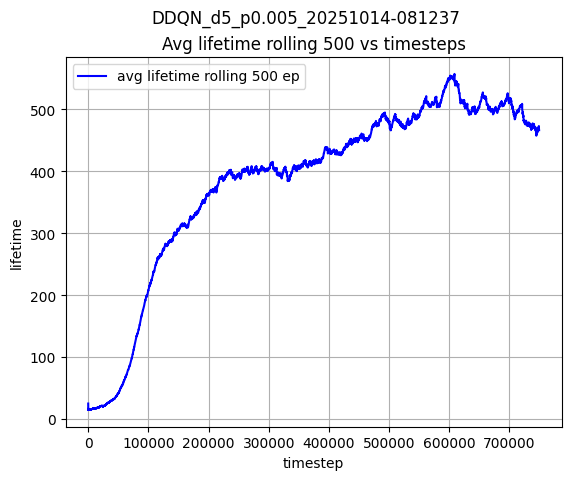

Mentre questi sono i grafici relativi all'addestramento con ppr nello stesso env e utilizzando una libreria di policy preaddestrate con 2  modelli [quelli relativi a p_err=0.001, p_err=0.003], utilizzando l'annealing per psi 0.85-->0.02 in 175k

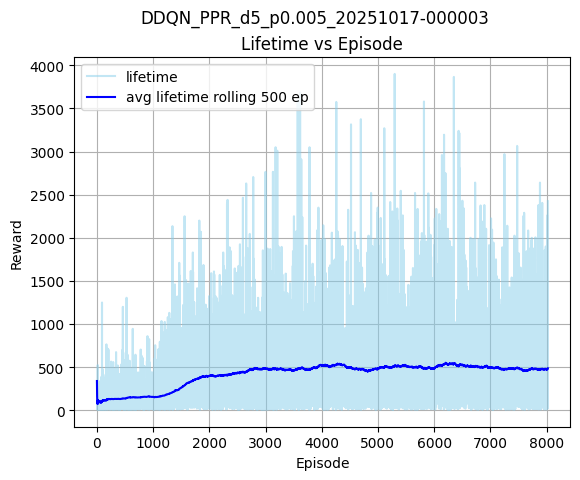
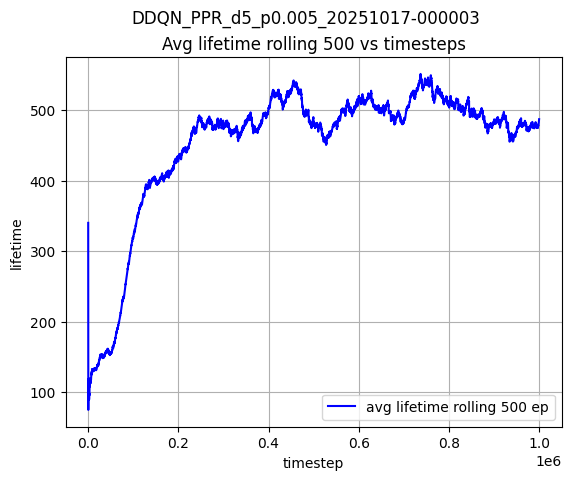